# 2. Data Understanding: Eksplorasi & Ekstraksi Fitur Warna Klasik Citra Alas Kaki

Tahap **Data Understanding** pada metodologi **CRISP-DM** bertujuan untuk memahami struktur, kualitas, distribusi kelas, resolusi, dan karakteristik statistik awal dari dataset citra kerapian sandal dan sepatu yang kini tersimpan di **`2-data_understanding/data/`**.

### Sasaran Tahap Ini:
1. **Verifikasi Struktur Direktori & Pemindahan Data:** Memastikan dataset di `2-data_understanding/data/` terbagi ke dalam 2 folder kelas:
   * `RAPI` (Alas kaki tertata sejajar, berpasangan teratur, atau di dalam rak).
   * `BERANTAKAN` (Alas kaki berserakan, bersilangan, atau bertumpuk acak).
2. **Audit Label & Duplikat:** Memeriksa hasil koreksi label terverifikasi dan mengidentifikasi berkas duplikat antar-kelompok.
3. **Visualisasi Sampel & Analisis Resolusi:** Menampilkan sampel gambar per kategori beserta ringkasan lebar, tinggi, dan aspek rasio.
4. **Ekstraksi Fitur Warna Klasik (*Classical Color Feature Extraction*):** Menghitung nilai **Rata-rata (*Mean*)** dan **Standar Deviasi (*Standard Deviation*)** untuk setiap kanal **Red, Green, Blue** pada seluruh citra lalu menyimpannya ke [`fitur_warna_klasik.csv`](fitur_warna_klasik.csv).


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageStat, ImageOps


def find_project_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / "src" / "10-project_citra"):
            if (candidate / "3-data_preparation").is_dir() and (candidate / "6-deployment").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Folder proyek 10-project_citra tidak ditemukan dari direktori kerja.")


PROJECT_DIR = find_project_dir()
sys.path.insert(0, str(PROJECT_DIR))
from pipeline import LABEL_OVERRIDES

# Lokasi dataset telah disesuaikan ke dalam folder 2-data_understanding/data
DATASET_DIR = PROJECT_DIR / "2-data_understanding" / "data"
CLASSES = ["RAPI", "BERANTAKAN"]


def effective_label(image_path, folder_label):
    override = LABEL_OVERRIDES.get(
        image_path.relative_to(DATASET_DIR).as_posix().casefold()
    )
    return override[0] if override is not None else folder_label


if not all((DATASET_DIR / cls).is_dir() for cls in CLASSES):
    raise FileNotFoundError(f"Folder kelas dataset tidak lengkap di: {DATASET_DIR}")

for cls in CLASSES:
    files = [f for f in (DATASET_DIR / cls).rglob("*") if f.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    print(f"Folder {cls:<12} -> {len(files)} berkas gambar")

total_raw = sum(len([f for f in (DATASET_DIR / cls).rglob('*') if f.suffix.lower() in {'.jpg', '.jpeg', '.png'}]) for cls in CLASSES)
print(f"Total Citra Mentah  -> {total_raw} berkas")

effective_counts = {"Berantakan": 0, "Rapi": 0}
for cls in CLASSES:
    source_label = 1 if cls == "RAPI" else 0
    for image_path in (DATASET_DIR / cls).rglob("*"):
        if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            corrected = effective_label(image_path, source_label)
            effective_counts["Rapi" if corrected == 1 else "Berantakan"] += 1

print("Distribusi setelah 4 koreksi label terverifikasi:", effective_counts)


Folder RAPI         -> 73 berkas gambar
Folder BERANTAKAN   -> 80 berkas gambar
Total Citra Mentah  -> 153 berkas
Distribusi setelah 4 koreksi label terverifikasi: {'Berantakan': 84, 'Rapi': 69}


---
## 2.1 Analisis Distribusi Kelas, Kelompok Pengambilan, & Resolusi Citra

Dataset mentah berjumlah **153 berkas citra** (73 folder `RAPI` dan 80 folder `BERANTAKAN`) dari 7 kelompok observasi. Setelah menerapkan 4 koreksi label terverifikasi (`LABEL_OVERRIDES`), distribusi efektif sebelum deduplikasi menjadi **69 Rapi (45,1%)** dan **84 Berantakan (54,9%)**. Distribusi antar-kelompok juga diaudit di bawah ini.


In [2]:
manifest = []
for cls in CLASSES:
    folder = DATASET_DIR / cls
    for image_path in sorted(folder.rglob("*")):
        if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            label = effective_label(image_path, 1 if cls == "RAPI" else 0)
            with Image.open(image_path) as img:
                img_t = ImageOps.exif_transpose(img)
                width, height = img_t.size
                manifest.append({
                    "filename": image_path.name,
                    "rel_path": image_path.relative_to(DATASET_DIR).as_posix(),
                    "folder_class": "Rapi" if cls == "RAPI" else "Berantakan",
                    "class": "Rapi" if label == 1 else "Berantakan",
                    "kelompok": image_path.parent.name.lower(),
                    "width": width,
                    "height": height,
                    "aspect_ratio": round(width / height, 2),
                    "format": img.format,
                    "mode": img.mode,
                })

df_info = pd.DataFrame(manifest)
print(f"Total citra terdata: {len(df_info)}")
print("\nDistribusi Jumlah Citra per Kelompok & Kelas Terkoreksi:")
display(df_info.groupby(["kelompok", "class"]).size().unstack(fill_value=0))
print("\nRingkasan Resolusi & Aspek Rasio Citra (setelah koreksi orientasi EXIF):")
display(df_info[["width", "height", "aspect_ratio"]].describe().round(2))


Total citra terdata: 153

Distribusi Jumlah Citra per Kelompok & Kelas Terkoreksi:


class,Berantakan,Rapi
kelompok,,
kelompok 1,11,7
kelompok 2,15,15
kelompok 3,15,2
kelompok 4,2,11
kelompok 5,15,15
kelompok 6,15,15
kelompok 7,11,4



Ringkasan Resolusi & Aspek Rasio Citra (setelah koreksi orientasi EXIF):


,width,height,aspect_ratio
count,153.00,153.00,153.00
mean,2767.57,2859.41,0.97
std,1378.29,1117.96,0.36
min,720.00,899.00,0.56
25%,1200.00,1600.00,0.75
50%,3048.00,3048.00,0.75
75%,4064.00,4064.00,1.33
max,9248.00,6944.00,1.78


---
## 2.2 Visualisasi Sampel Citra per Kategori

Berikut adalah galeri visualisasi sampel representatif dari kategori **Rapi** dan **Berantakan** setelah koreksi orientasi EXIF:


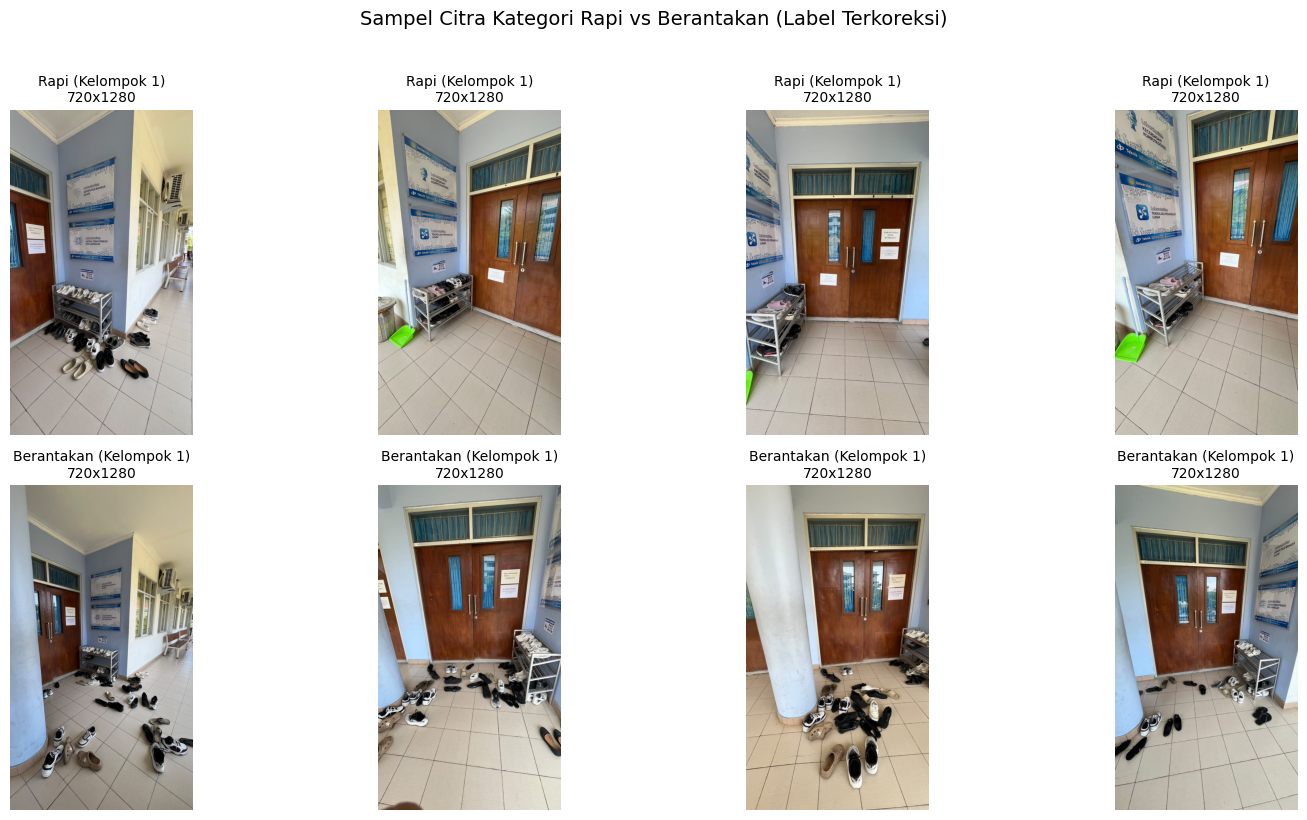

In [3]:
def plot_samples(dataset_dir, classes, n_cols=4):
    fig, axes = plt.subplots(len(classes), n_cols, figsize=(16, 4 * len(classes)))
    for row_idx, cls in enumerate(classes):
        target_label = 1 if cls == "RAPI" else 0
        img_files = []
        for path in sorted(dataset_dir.rglob("*")):
            if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            source_label = 1 if path.relative_to(dataset_dir).parts[0].casefold() == "rapi" else 0
            if effective_label(path, source_label) == target_label:
                img_files.append(path)
            if len(img_files) == n_cols:
                break
        for col_idx, path in enumerate(img_files):
            ax = axes[row_idx, col_idx]
            with Image.open(path) as img:
                img_t = ImageOps.exif_transpose(img).convert("RGB")
                ax.imshow(img_t)
                label_name = "Rapi" if target_label == 1 else "Berantakan"
                ax.set_title(f"{label_name} ({path.parent.name})\n{img_t.width}x{img_t.height}", fontsize=10)
                ax.axis("off")
        for col_idx in range(len(img_files), n_cols):
            axes[row_idx, col_idx].axis("off")
    plt.suptitle("Sampel Citra Kategori Rapi vs Berantakan (Label Terkoreksi)", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()


plot_samples(DATASET_DIR, CLASSES)


---
## 2.3 Ekstraksi Fitur Warna Klasik (Rata-rata & Standar Deviasi Kanal R, G, B)

Sesuai spesifikasi tugas awal, untuk setiap citra dalam dataset diekstraksi fitur statistik warna klasik pada masing-masing kanal (**Red, Green, Blue**) menggunakan rumus:

$$\mu_c = \frac{1}{N} \sum_{i=1}^{N} P_{c}(i) \quad \text{dan} \quad \sigma_c = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (P_{c}(i) - \mu_c)^2}$$

di mana $c \in \{\text{Red}, \text{Green}, \text{Blue}\}$ dan $N = W \times H$.


In [4]:
def extract_classical_color_features(dataset_dir, classes):
    records = []
    for cls_name in classes:
        folder = dataset_dir / cls_name
        files = sorted([f for f in folder.rglob("*") if f.suffix.lower() in {".jpg", ".jpeg", ".png"}])
        for image_path in files:
            with Image.open(image_path) as img:
                image_rgb = ImageOps.exif_transpose(img).convert("RGB")
                width, height = image_rgb.size
                stats = ImageStat.Stat(image_rgb)
                red_mean, green_mean, blue_mean = stats.mean
                red_std, green_std, blue_std = stats.stddev
                label = effective_label(image_path, 1 if cls_name == "RAPI" else 0)
                class_name = "Rapi" if label == 1 else "Berantakan"
                records.append({
                    "filename": image_path.name,
                    "rel_path": image_path.relative_to(dataset_dir).as_posix(),
                    "class": class_name,
                    "label": label,
                    "width": width,
                    "height": height,
                    "mean_red": round(red_mean, 4),
                    "std_red": round(red_std, 4),
                    "mean_green": round(green_mean, 4),
                    "std_green": round(green_std, 4),
                    "mean_blue": round(blue_mean, 4),
                    "std_blue": round(blue_std, 4),
                    "mean_overall": round((red_mean + green_mean + blue_mean) / 3, 4),
                    "std_overall": round((red_std + green_std + blue_std) / 3, 4),
                })
    return pd.DataFrame(records)


df_features = extract_classical_color_features(DATASET_DIR, CLASSES)
output_path = PROJECT_DIR / "2-data_understanding" / "fitur_warna_klasik.csv"
df_features.to_csv(output_path, index=False)
print(f"Ekstraksi selesai: {len(df_features)} baris disimpan di {output_path}")
display(df_features.head(10))


Ekstraksi selesai: 153 baris disimpan di D:\university\semester 5_book\proyek sain data\src\10-project_citra\2-data_understanding\fitur_warna_klasik.csv


,filename,rel_path,class,label,width,height,mean_red,std_red,mean_green,std_green,mean_blue,std_blue,mean_overall,std_overall
0,berantakan 1.jpeg,RAPI/Kelompok 1/berantakan 1.jpeg,Berantakan,0,3120,4160,146.3772,64.4177,134.3311,65.5840,121.7822,64.6816,134.1635,64.8944
1,berantakan 2.jpeg,RAPI/Kelompok 1/berantakan 2.jpeg,Berantakan,0,3120,4160,150.2323,58.4907,139.2655,64.1145,126.2393,68.5687,138.5790,63.7247
2,WhatsApp Image 2026-11-08 at 17.44.49.jpeg,RAPI/Kelompok 1/WhatsApp Image 2026-11-08 at 1...,Rapi,1,720,1280,145.4923,56.3417,140.6887,57.8603,134.5066,56.6562,140.2292,56.9527
3,WhatsApp Image 2026-11-08 at 17.44.50.jpeg,RAPI/Kelompok 1/WhatsApp Image 2026-11-08 at 1...,Rapi,1,720,1280,150.9721,49.9047,143.2377,54.3076,130.0064,57.1058,141.4054,53.7727
4,WhatsApp Image 2026-11-08 at 17.44.52.jpeg,RAPI/Kelompok 1/WhatsApp Image 2026-11-08 at 1...,Rapi,1,720,1280,144.0170,53.4220,136.6763,59.9991,129.1112,66.1612,136.6015,59.8608
5,WhatsApp Image 2026-11-08 at 17.44.54.jpeg,RAPI/Kelompok 1/WhatsApp Image 2026-11-08 at 1...,Rapi,1,720,1280,143.9395,53.0367,136.8029,57.4552,124.9063,63.6509,135.2163,58.0476
6,WhatsApp Image 2026-11-08 at 17.44.57.jpeg,RAPI/Kelompok 1/WhatsApp Image 2026-11-08 at 1...,Berantakan,0,720,1280,143.1505,53.9922,140.7057,59.3940,134.9173,62.7099,139.5912,58.6987
7,WhatsApp Image 2026-11-08 at 17.44.57_1.jpeg,RAPI/Kelompok 1/WhatsApp Image 2026-11-08 at 1...,Berantakan,0,720,1280,145.8850,54.8058,143.5616,61.5388,137.0198,65.6955,142.1555,60.6800
8,WhatsApp Image 2026-11-09 at 10.58.02.jpeg,RAPI/Kelompok 1/WhatsApp Image 2026-11-09 at 1...,Rapi,1,960,1280,143.8995,53.8819,136.6204,61.0581,130.4808,68.8257,137.0003,61.2552
9,WhatsApp Image 2026-11-09 at 10.58.03 (1).jpeg,RAPI/Kelompok 1/WhatsApp Image 2026-11-09 at 1...,Rapi,1,960,1280,149.9969,59.0731,142.0432,64.0845,135.2312,65.0698,142.4238,62.7425


---
## 2.4 Analisis Perbandingan Fitur Warna Rata-rata & Standar Deviasi Antar-Kelas

Pengamatan di bawah menunjukkan perbedaan statistik warna antara kelas `Rapi` dan `Berantakan`.


In [5]:
summary = df_features.groupby("class")[
    ["mean_red", "std_red", "mean_green", "std_green", "mean_blue", "std_blue", "mean_overall", "std_overall"]
].mean()
print("=== Rata-rata Fitur Warna Klasik Berdasarkan Kelas ===")
display(summary.round(3))


=== Rata-rata Fitur Warna Klasik Berdasarkan Kelas ===


,mean_red,std_red,mean_green,std_green,mean_blue,std_blue,mean_overall,std_overall
class,,,,,,,,
Berantakan,146.950,60.230,132.597,62.031,120.112,62.729,133.220,61.663
Rapi,127.303,57.135,119.594,59.402,112.068,60.133,119.655,58.890


---
## 2.5 Kesimpulan & Temuan Penting Tahap Data Understanding

1. **Integritas Lokasi Dataset:** Seluruh **153 citra** dari 14 subdirektori kelompok di **`2-data_understanding/data/`** berhasil dimuat dan diaudit.
2. **Keberagaman Latar & Resolusi:** Gambar memiliki resolusi dan aspek rasio yang bervariasi antar-kelompok (dengan warna lantai/karpet yang berbeda-beda antar-lokasi pengambilan). Hal ini menjadi dasar penting pada Tahap 3 (*Data Preparation*) agar model tidak hanya menghafal warna lantai rata-rata (*mean RGB*), melainkan mempelajari fitur keragaman warna (`std`), struktur gradien, orientasi, spektrum FFT, dan tekstur yang invarian terhadap lokasi.
3. **Artefak Tabular Awal:** Tabel fitur warna klasik (Rata-rata & Standar Deviasi per kanal RGB) telah tersimpan di [`fitur_warna_klasik.csv`](fitur_warna_klasik.csv).
